# 2nd round - Step 2: cleaning

Rules: **fix only what is provably wrong** (the data themselves show the error), **log every
change** (`reports/02_cleaning/cleaning_log.csv`) and flag every changed row (`dq_` columns),
**never drop** policy, customer, address or weather rows (only exact duplicate claims are removed),
and **do not impute** missing values (step 3 decides how each one is handled).

The script `python 02_data_cleaning.py` writes `data/clean/` (same file names as the case study).
This notebook applies the same functions rule by rule and shows each rule's effect.

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")

cleaning = importlib.import_module("02_data_cleaning")
raw = {n: H.read_table(n, "raw") for n in C.TABLES}
log = H.ChangeLog("notebook")

2nd round - emerging market - IAA AI-Assisted Hackathon 2026 - Part 2


## 1. Identifiers: lost leading zeros

In [2]:
def lengths(s):
    return {int(k): int(v) for k, v in s.str.len().value_counts().sort_index().items()}

for t in C.POLICY_TABLES:
    before = lengths(raw[t]["customer_id"])
    after = lengths(cleaning.pad_ids(raw[t], t, log)["customer_id"])
    print(f"{t:<20} customer_id lengths before {before} -> after {after}")

policies_motor       customer_id lengths before {8: 47283} -> after {8: 47283}
policies_buildings   customer_id lengths before {8: 27447} -> after {8: 27447}
policies_contents    customer_id lengths before {8: 34566} -> after {8: 34566}
test_motor           customer_id lengths before {8: 90521} -> after {8: 90521}
test_buildings       customer_id lengths before {8: 52295} -> after {8: 52295}
test_contents        customer_id lengths before {8: 66247} -> after {8: 66247}


## 2. Exposure recomputed from the dates

In [3]:
fixed = {t: cleaning.fix_exposure(raw[t], t, log) for t in C.POLICY_TABLES}
t = "policies_motor"
d = fixed[t]
bad = d["dq_exposure_fixed"] == 1
pd.DataFrame({"exposure as recorded": raw[t].loc[bad, "exposure"].head(8).to_numpy(),
              "days on cover": ((d["period_end"] - d["period_start"]).dt.days + 1)[bad].head(8).to_numpy(),
              "exposure fixed": d.loc[bad, "exposure"].head(8).round(4).to_numpy()})

  [C04] policies_motor.exposure: exposure recomputed from the period dates (days / 365) -> 249 rows (recomputed)
  [C04] policies_buildings.exposure: exposure recomputed from the period dates (days / 365) -> 152 rows (recomputed)
  [C04] policies_contents.exposure: exposure recomputed from the period dates (days / 365) -> 194 rows (recomputed)


,exposure as recorded,days on cover,exposure fixed
0,1.0139,365,1.0000
1,1.0139,365,1.0000
2,1.0139,365,1.0000
3,0.8389,302,0.8274
4,1.0139,365,1.0000
5,1.0139,365,1.0000
6,1.0139,365,1.0000
7,1.0139,365,1.0000


## 3. Sums insured recorded in units instead of thousands

  [C05] policies_buildings.sum_insured: sum insured > 100x the median (229,000) divided by 1,000 -> 53 rows (rescaled)


  [C05] policies_contents.sum_insured: sum insured > 100x the median (35,800) divided by 1,000 -> 57 rows (rescaled)


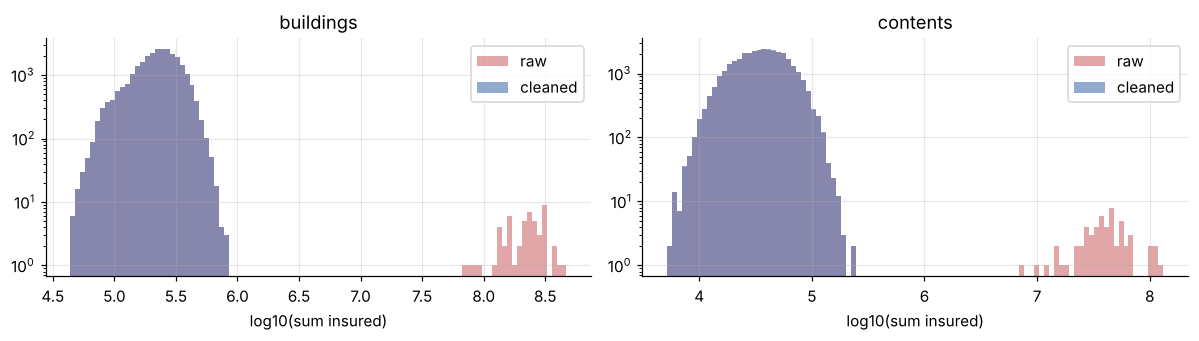

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, line in zip(axes, ["buildings", "contents"]):
    t = f"policies_{line}"
    after = cleaning.fix_sum_insured(raw[t], t, log)
    bins = np.histogram_bin_edges(np.log10(raw[t]["sum_insured"].dropna()), bins=100)  # same bins for both
    ax.hist(np.log10(raw[t]["sum_insured"]), bins=bins, alpha=0.5, label="raw", color="#C44E52")
    ax.hist(np.log10(after["sum_insured"]), bins=bins, alpha=0.6, label="cleaned", color="#4C72B0")
    ax.set_yscale("log"); ax.set_xlabel("log10(sum insured)"); ax.set_title(line); ax.legend()
plt.tight_layout(); plt.show()

## 4. One spelling per category

In [5]:
cust = cleaning.normalise_codes(raw["customers"], "customers", log)
cust = cleaning.split_self_employed(cust, "customers", log)
b = cleaning.normalise_codes(raw["policies_buildings"], "policies_buildings", log)
pd.DataFrame({"raw": raw["policies_buildings"]["construction_type"].value_counts(),
              "cleaned": b["construction_type"].value_counts()}).fillna(0).astype(int)

  [C01] customers.gender: one spelling per category (trim, case, local codes) -> 135,856 rows (recoded)
  [C01] customers.occupation: one spelling per category (trim, case, local codes) -> 89,397 rows (recoded)
  [C02] customers.occupation: 'self-employed' prefix split into its own flag -> 11,975 rows (new column self_employed)
  [C01] policies_buildings.construction_type: one spelling per category (trim, case, local codes) -> 27,447 rows (recoded)


,raw,cleaned
construction_type,,
BRK,19194,0
MIX,2781,0
STN,2170,0
WOD,3302,0
brick,0,19194
non_standard,0,2781
stone,0,2170
timber,0,3302


In [6]:
print("occupations:", cust["occupation"].nunique(), "levels after cleaning (raw:", raw["customers"]["occupation"].nunique(), ")")
if "self_employed" in cust:
    print("self-employed customers:", int(cust["self_employed"].sum()))

occupations: 20 levels after cleaning (raw: 80 )
self-employed customers: 11975


## 5. Driver history: impossible years licensed (1st round)
A driver's age at first licence is the same in every row of a policy. Rows where it falls below 17 take it from the policy's other rows; a policy without another row is capped at age - 17.

In [7]:
tabs = {t: cleaning.pad_ids(raw[t], t, log) for t in ("policies_motor", "test_motor")}
if "driver_age" in tabs["policies_motor"]:
    rep = cleaning.repair_years_licensed(dict(tabs), log)
    m0, m1 = tabs["policies_motor"], rep["policies_motor"]
    ex = m1.loc[m1["dq_years_licensed_fixed"] == 1, "policy_id"].iloc[0]
    view = m0.loc[m0["policy_id"] == ex, ["policy_id", "period_start", "driver_age", "years_licensed"]].copy()
    view["years_licensed cleaned"] = m1.loc[m1["policy_id"] == ex, "years_licensed"].to_numpy()
    view["age at first licence (raw)"] = view["driver_age"] - view["years_licensed"]
    display(view)
else:
    print("2nd round: age bands only, the check is not possible")

2nd round: age bands only, the check is not possible


## 6. Claims
Exact duplicates under a second id, the reserve entry error, the claim cost of the case study, the link to the policy row on cover, and claims outside the cover bought.

In [8]:
rows = []
for line in C.LINES:
    p = cleaning.pad_ids(raw[f"policies_{line}"], f"policies_{line}", log)
    rows.append(p[["row_id", "policy_id", "period_start", "period_end"] +
                  [c for c in ("cover_type", "accidental_damage_cover") if c in p]])
rows = pd.concat(rows, ignore_index=True)
claims = cleaning.clean_claims(cleaning.normalise_codes(raw["claims"], "claims", log), rows, log)
print(f"claims: {len(raw['claims']):,} raw -> {len(claims):,} clean")
claims["match_status"].value_counts()

  [K03] claims.net_incurred: claim cost = incurred - recoveries (floored at 0); 0 if repudiated -> 9,258 rows (new column)


  [K04] claims.row_id: claim linked to the policy row on cover at the loss date -> 36 rows (unmatched kept, flagged (excluded from targets))
  [K05] claims.peril: motor claim of a peril the cover does not include -> 0 rows (kept, flagged)
  [K06] claims.peril: accidental-damage claim on a row without AD cover -> 74 rows (kept, flagged)
claims: 9,258 raw -> 9,258 clean


match_status
matched             9222
before_first_row      36
Name: count, dtype: int64

## 7. The cleaning log of the full run
Written by `python 02_data_cleaning.py`: one line per rule and table.

In [9]:
log_full = pd.read_csv(C.REPORTS / "02_cleaning" / "cleaning_log.csv")
log_full[["rule_id", "table", "column", "rule", "rows_affected", "action", "evidence"]]

,rule_id,table,column,rule,rows_affected,action,evidence
0,C01,customers,gender,"one spelling per category (trim, case, local codes)",135856,recoded,"'F'->'f' (67,973); 'M'->'m' (67,883)"
1,C01,customers,occupation,"one spelling per category (trim, case, local codes)",89397,recoded,"'Retired'->'retired' (9,218); 'Student'->'student' (6,445); 'Retired '->'retired' (2,736); 'Care worker'->'care work..."
2,C02,customers,occupation,'self-employed' prefix split into its own flag,11975,new column self_employed,20 base occupations remain
3,C10,weather,*,negative weather measures,0,none found,NaN
4,C04,policies_motor,exposure,exposure recomputed from the period dates (days / 365),249,recomputed,recorded in days: 47; on a 360-day basis: 202; other: 0
5,C04,policies_buildings,exposure,exposure recomputed from the period dates (days / 365),152,recomputed,recorded in days: 33; on a 360-day basis: 119; other: 0
6,C05,policies_buildings,sum_insured,"sum insured > 100x the median (229,000) divided by 1,000",53,rescaled,"after the fix: 73,000 to 470,000 (median 229,000)"
7,C01,policies_buildings,construction_type,"one spelling per category (trim, case, local codes)",27447,recoded,"'BRK'->'brick' (19,194); 'WOD'->'timber' (3,302); 'MIX'->'non_standard' (2,781); 'STN'->'stone' (2,170)"
8,C04,policies_contents,exposure,exposure recomputed from the period dates (days / 365),194,recomputed,recorded in days: 34; on a 360-day basis: 160; other: 0
9,C05,policies_contents,sum_insured,"sum insured > 100x the median (35,800) divided by 1,000",57,rescaled,"after the fix: 7,600 to 131,600 (median 39,100)"


## 8. After cleaning
Every key and link check of step 1 is run again on the cleaned tables, and the missing values left are listed (step 3 tests whether each gap is informative).

In [10]:
after = pd.read_csv(C.REPORTS / "02_cleaning" / "checks_after_cleaning.csv")
print(f"{int(after['passed'].sum())} of {len(after)} checks pass")
display(after.loc[~after["passed"]])
mv = pd.read_csv(C.REPORTS / "02_cleaning" / "missing_values.csv")
mv.loc[mv["table"] != "reference_policies"].sort_values("missing_pct", ascending=False).head(25)

60 of 60 checks pass


,table,check,failures,checked,passed,detail


,table,column,missing,missing_pct
25,claims,third_party_id,6545,70.696
24,claims,repairer_id,4283,46.263
4,customers,campaign_code,27433,20.193
60,expenses,emerging,1,12.500
15,policies_contents,security_level,4238,12.261
17,test_motor,vehicle_age,11070,12.229
0,customers,occupation,16517,12.158
18,test_motor,engine_size_cc,11004,12.156
22,test_contents,security_level,8050,12.151
11,policies_motor,engine_size_cc,5745,12.150


In [11]:
pd.DataFrame([{"table": n, "rows": len(H.read_table(n, "clean", columns=[H.read_table(n, "clean").columns[0]]))}
              for n in C.TABLES])

,table,rows
0,customers,135856
1,addresses,136914
2,weather,410742
3,claims,9258
4,policies_motor,47283
5,policies_buildings,27447
6,policies_contents,34566
7,test_motor,90521
8,test_buildings,52295
9,test_contents,66247
